In [5]:
from itertools import product
import numpy as np

K = 8
base = K + 1

count_triples = np.array([
    triple for triple in product(range(K + 1), repeat=3)
    if 1 <= sum(triple) <= K
])

slowing_counts = count_triples[:, 0]
steady_counts = count_triples[:, 1]
speeding_counts = count_triples[:, 2]

encoded_sums = (
    slowing_counts
    + base * steady_counts
    + (base ** 2) * speeding_counts
)


decoded_slowing = encoded_sums % base
decoded_steady = (encoded_sums // base) % base
decoded_speeding = encoded_sums // (base ** 2)

assert len(np.unique(encoded_sums)) == len(encoded_sums)
assert np.array_equal(decoded_slowing, slowing_counts)
assert np.array_equal(decoded_steady, steady_counts)
assert np.array_equal(decoded_speeding, speeding_counts)

print(f"Passed: all {len(count_triples)} triples are unique and decoded correctly.")

Passed: all 164 triples are unique and decoded correctly.


Fitted coefficients: a = 0.0000, b = 0.5000


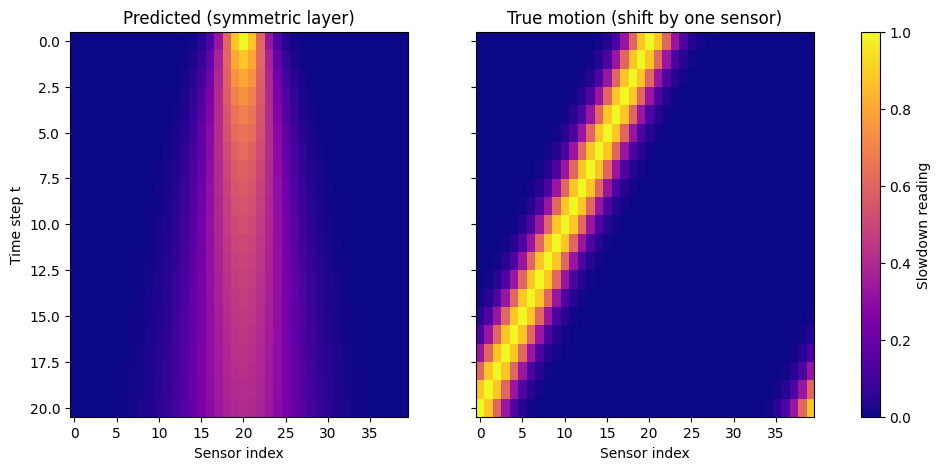

In [2]:
"""Q2(a): fit the symmetric ring-road layer and compare its 20-step rollout
with the true backward shift of a smooth bump (heatmaps)."""
import numpy as np
import matplotlib.pyplot as plt

NUM_SENSORS = 40
NUM_STEPS = 20
ISOLATED_SENSOR = 20
BUMP_CENTER = 20
BUMP_VARIANCE_FACTOR = 8         
OUTPUT_PATH = "../report/figures/q2a_heatmaps.pdf"


def true_shift_step(snapshot):
    """True motion rule: x_i(t+1) = x_{i+1}(t), with ring wrap-around."""
    return np.roll(snapshot, -1)


def build_features(snapshot):
    """Return the (num_sensors, 2) feature matrix [x_i, x_{i-1} + x_{i+1}]."""
    own_reading = snapshot
    neighbor_sum = np.roll(snapshot, 1) + np.roll(snapshot, -1)
    return np.column_stack([own_reading, neighbor_sum])


def fit_symmetric_layer():
    """Least-squares fit of (a, b) on the isolated-slowdown snapshot (Q2 a-i)."""
    isolated_snapshot = np.zeros(NUM_SENSORS)
    isolated_snapshot[ISOLATED_SENSOR] = 1.0
    target_snapshot = true_shift_step(isolated_snapshot)

    features = build_features(isolated_snapshot)
    (self_coeff, neighbor_coeff), *_ = np.linalg.lstsq(
        features, target_snapshot, rcond=None
    )
    return self_coeff, neighbor_coeff


def symmetric_layer_step(snapshot, self_coeff, neighbor_coeff):
    """Predicted next snapshot: a * x_i + b * (x_{i-1} + x_{i+1})."""
    return build_features(snapshot) @ np.array([self_coeff, neighbor_coeff])


def rollout(initial_snapshot, step_function, num_steps):
    """Return array of shape (num_steps + 1, num_sensors); row t is time t."""
    history = [initial_snapshot]
    for _ in range(num_steps):
        history.append(step_function(history[-1]))
    return np.stack(history)


def main():
    self_coeff, neighbor_coeff = fit_symmetric_layer()
    print(f"Fitted coefficients: a = {self_coeff:.4f}, b = {neighbor_coeff:.4f}")

    sensor_indices = np.arange(NUM_SENSORS)
    initial_bump = np.exp(-((sensor_indices - BUMP_CENTER) ** 2) / BUMP_VARIANCE_FACTOR)

    predicted_history = rollout(
        initial_bump,
        lambda s: symmetric_layer_step(s, self_coeff, neighbor_coeff),
        NUM_STEPS,
    )
    true_history = rollout(initial_bump, true_shift_step, NUM_STEPS)

    shared_min = min(predicted_history.min(), true_history.min())
    shared_max = max(predicted_history.max(), true_history.max())

    fig, (ax_pred, ax_true) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    panels = [
        (ax_pred, predicted_history, "Predicted (symmetric layer)"),
        (ax_true, true_history, "True motion (shift by one sensor)"),
    ]
    for axis, history, title in panels:
        image = axis.imshow(
            history, aspect="auto", origin="upper",
            vmin=shared_min, vmax=shared_max, cmap="plasma",
        )
        axis.set_title(title)
        axis.set_xlabel("Sensor index")
    ax_pred.set_ylabel("Time step t")
    fig.colorbar(image, ax=[ax_pred, ax_true], label="Slowdown reading")

    fig.savefig(OUTPUT_PATH, bbox_inches="tight")
    plt.show()


if __name__ == "__main__":
    main()